In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

In [2]:
superSeed = 42
torch.manual_seed(superSeed)
np.random.seed(superSeed)


In [3]:
import kagglehub

path = kagglehub.dataset_download("alfathterry/telco-customer-churn-11-1-3")
print("Dataset downloaded to:", path)

df = pd.read_csv(path + "/telco.csv")
print(df.head())


Dataset downloaded to: C:\Users\nbadr\.cache\kagglehub\datasets\alfathterry\telco-customer-churn-11-1-3\versions\1
  Customer ID  Gender  Age Under 30 Senior Citizen Married Dependents  \
0  8779-QRDMV    Male   78       No            Yes      No         No   
1  7495-OOKFY  Female   74       No            Yes     Yes        Yes   
2  1658-BYGOY    Male   71       No            Yes      No        Yes   
3  4598-XLKNJ  Female   78       No            Yes     Yes        Yes   
4  4846-WHAFZ  Female   80       No            Yes     Yes        Yes   

   Number of Dependents        Country       State  ...  \
0                     0  United States  California  ...   
1                     1  United States  California  ...   
2                     3  United States  California  ...   
3                     1  United States  California  ...   
4                     1  United States  California  ...   

  Total Extra Data Charges  Total Long Distance Charges  Total Revenue  \
0                

In [4]:
df = df.drop(["Customer ID","Churn Score","CLTV","Churn Category","Churn Reason"], axis=1)

# TotalCharges has whitespace → convert to numeric
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

# Handle missing values
df = df.dropna()

# Split target from features
y = df["Churn Label"].map({"Yes": 1, "No": 0}).values
X = df.drop("Churn Label", axis=1)


# ----------------------------------------------------------
# 3. ENCODE CATEGORICAL FEATURES
# ----------------------------------------------------------

# Identify categorical + numerical columns
categorical_cols = X.select_dtypes(include=["object"]).columns
numeric_cols = X.select_dtypes(exclude=["object"]).columns

# One-hot encode categorical columns
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_cat = encoder.fit_transform(X[categorical_cols])

# Scale numeric columns
scaler = StandardScaler()
X_num = scaler.fit_transform(X[numeric_cols])

# Combine both
X_processed = np.hstack([X_num, X_cat])

print("Final feature shape:", X_processed.shape)

Final feature shape: (2493, 1011)


In [5]:
# Get encoded categorical feature names
cat_feature_names = encoder.get_feature_names_out(categorical_cols)

# Combine numeric + encoded categorical names
all_feature_names = list(numeric_cols) + list(cat_feature_names)

print("Number of features:", len(all_feature_names))
print("\nFeature names:\n")
for f in all_feature_names:
    print(f)

    

Number of features: 1011

Feature names:

Age
Number of Dependents
Zip Code
Latitude
Longitude
Population
Number of Referrals
Tenure in Months
Avg Monthly Long Distance Charges
Avg Monthly GB Download
Monthly Charge
Total Charges
Total Refunds
Total Extra Data Charges
Total Long Distance Charges
Total Revenue
Satisfaction Score
Gender_Female
Gender_Male
Under 30_No
Under 30_Yes
Senior Citizen_No
Senior Citizen_Yes
Married_No
Married_Yes
Dependents_No
Dependents_Yes
Country_United States
State_California
City_Acampo
City_Acton
City_Adelanto
City_Adin
City_Aguanga
City_Ahwahnee
City_Alamo
City_Albany
City_Albion
City_Alderpoint
City_Alhambra
City_Aliso Viejo
City_Alpaugh
City_Alpine
City_Alta
City_Altadena
City_Alturas
City_Alviso
City_Amboy
City_Anaheim
City_Anderson
City_Angels Camp
City_Angelus Oaks
City_Angwin
City_Annapolis
City_Antioch
City_Anza
City_Apple Valley
City_Applegate
City_Aptos
City_Arcata
City_Armona
City_Arnold
City_Aromas
City_Arroyo Grande
City_Artesia
City_Atascader

In [6]:

X_train, X_val, y_train, y_val = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

In [7]:
# 5. PYTORCH DATASETS + DATALOADERS
# ----------------------------------------------------------

class TelcoDataset(Dataset):
    def __init__(self, features, labels):
        self.X = features
        self.y = labels.float().unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = TelcoDataset(X_train, y_train)
val_dataset = TelcoDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32)
val_loader   = DataLoader(val_dataset, batch_size=32)

In [8]:


class ChurnModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        
        
        self.conv1 = nn.Conv1d(1,4,3)
        self.bn1 = nn.BatchNorm1d(4)
        
            
        self.conv2 = nn.Conv1d(4,8,3)
        self.bn2 = nn.BatchNorm1d(8)
        
        self.conv3 = nn.Conv1d(8,16,3)
        self.bn3 = nn.BatchNorm1d(16)
        
        self.conv4 = nn.Conv1d(16,32,3)
        self.bn4 = nn.BatchNorm1d(32)
        
        self.relu1 = nn.ReLU()
        self.aap1 = nn.AdaptiveAvgPool1d(1)
            
        self.model = nn.Sequential(
            
                       
            nn.Linear(input_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(128, 32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            
            nn.Linear(32, 8),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(8,1)
        )
    def forward(self, x):
        #x = x.unsqueeze(1)
        #x = self.relu1(self.bn1(self.conv1(x)))
        #x = self.relu1(self.bn2(self.conv2(x)))
        #x = self.relu1(self.bn3(self.conv3(x)))
        #x = self.relu1(self.bn4(self.conv4(x)))
        #x = self.aap1(x)
        #x = x.squeeze(-1)
        return self.model(x)

In [9]:
# Src: https://www.dataquest.io/blog/sequence-models-in-pytorch/
# Src: https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html
# Src: https://stackoverflow.com/questions/6541123/improve-subplot-size-spacing-with-many-subplots
# ----------------------------------------------------------

def train(model, train_loader, val_loader, device, epochs=50, lr=0.001):

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model = model.to(device)
    epochArr = []
    trainLossArr = []
    valLossArr = []
    valAccArr = []

    for epoch in range(epochs):

        # TRAIN MODE
        model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        # VALIDATION MODE
        model.eval()
        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                y_pred = model(X_batch)
                loss = criterion(y_pred, y_batch)
                val_loss += loss.item()

                predicted = (torch.sigmoid(y_pred) >= 0.5).float()
                
                correct += (predicted == y_batch).sum().item()
                total += y_batch.size(0)

        accuracy = correct / total
        
        epochArr.append(epoch+1)
        trainLossArr.append(train_loss)
        valLossArr.append(val_loss)
        valAccArr.append(accuracy)
        
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {accuracy:.4f}")
        
    fig, (axTrainLoss, axValLoss, axAcc) = plt.subplots(3,figsize=(16,16))
    axTrainLoss.plot(epochArr,trainLossArr,'tab:orange')
    axTrainLoss.set_title('Training Loss')
    axTrainLoss.set_xlabel('Epoches')
    axTrainLoss.set_ylabel('Loss')
    axTrainLoss.grid(True)
    
    axValLoss.plot(epochArr,valLossArr,'tab:red')
    axValLoss.set_title('Validation Loss')
    axValLoss.set_xlabel('Epoches')
    axValLoss.set_ylabel('Loss')
    axValLoss.grid(True)
    
    axAcc.plot(epochArr,valAccArr,'tab:green')
    axAcc.set_title('Validation Accuracy')
    axAcc.set_xlabel('Epoches')
    axAcc.set_ylabel('Accuracy')
    axAcc.grid(True)
    
    fig.tight_layout()

In [10]:
!pip install --upgrade sympy


Epoch 1/100 | Train Loss: 27.8771 | Val Loss: 1.7142 | Val Acc: 0.9800
Epoch 2/100 | Train Loss: 3.6044 | Val Loss: 0.0615 | Val Acc: 0.9980
Epoch 3/100 | Train Loss: 2.0003 | Val Loss: 0.0132 | Val Acc: 1.0000
Epoch 4/100 | Train Loss: 1.6395 | Val Loss: 0.5234 | Val Acc: 0.9880
Epoch 5/100 | Train Loss: 1.1543 | Val Loss: 0.0271 | Val Acc: 1.0000
Epoch 6/100 | Train Loss: 1.0039 | Val Loss: 0.0048 | Val Acc: 1.0000
Epoch 7/100 | Train Loss: 0.8017 | Val Loss: 0.0017 | Val Acc: 1.0000
Epoch 8/100 | Train Loss: 1.0420 | Val Loss: 0.0002 | Val Acc: 1.0000
Epoch 9/100 | Train Loss: 1.0011 | Val Loss: 0.0001 | Val Acc: 1.0000
Epoch 10/100 | Train Loss: 0.7488 | Val Loss: 0.0001 | Val Acc: 1.0000
Epoch 11/100 | Train Loss: 0.9496 | Val Loss: 0.0000 | Val Acc: 1.0000
Epoch 12/100 | Train Loss: 0.9841 | Val Loss: 0.0000 | Val Acc: 1.0000
Epoch 13/100 | Train Loss: 0.5109 | Val Loss: 0.0000 | Val Acc: 1.0000
Epoch 14/100 | Train Loss: 1.2166 | Val Loss: 0.9279 | Val Acc: 0.9880
Epoch 15/100 |

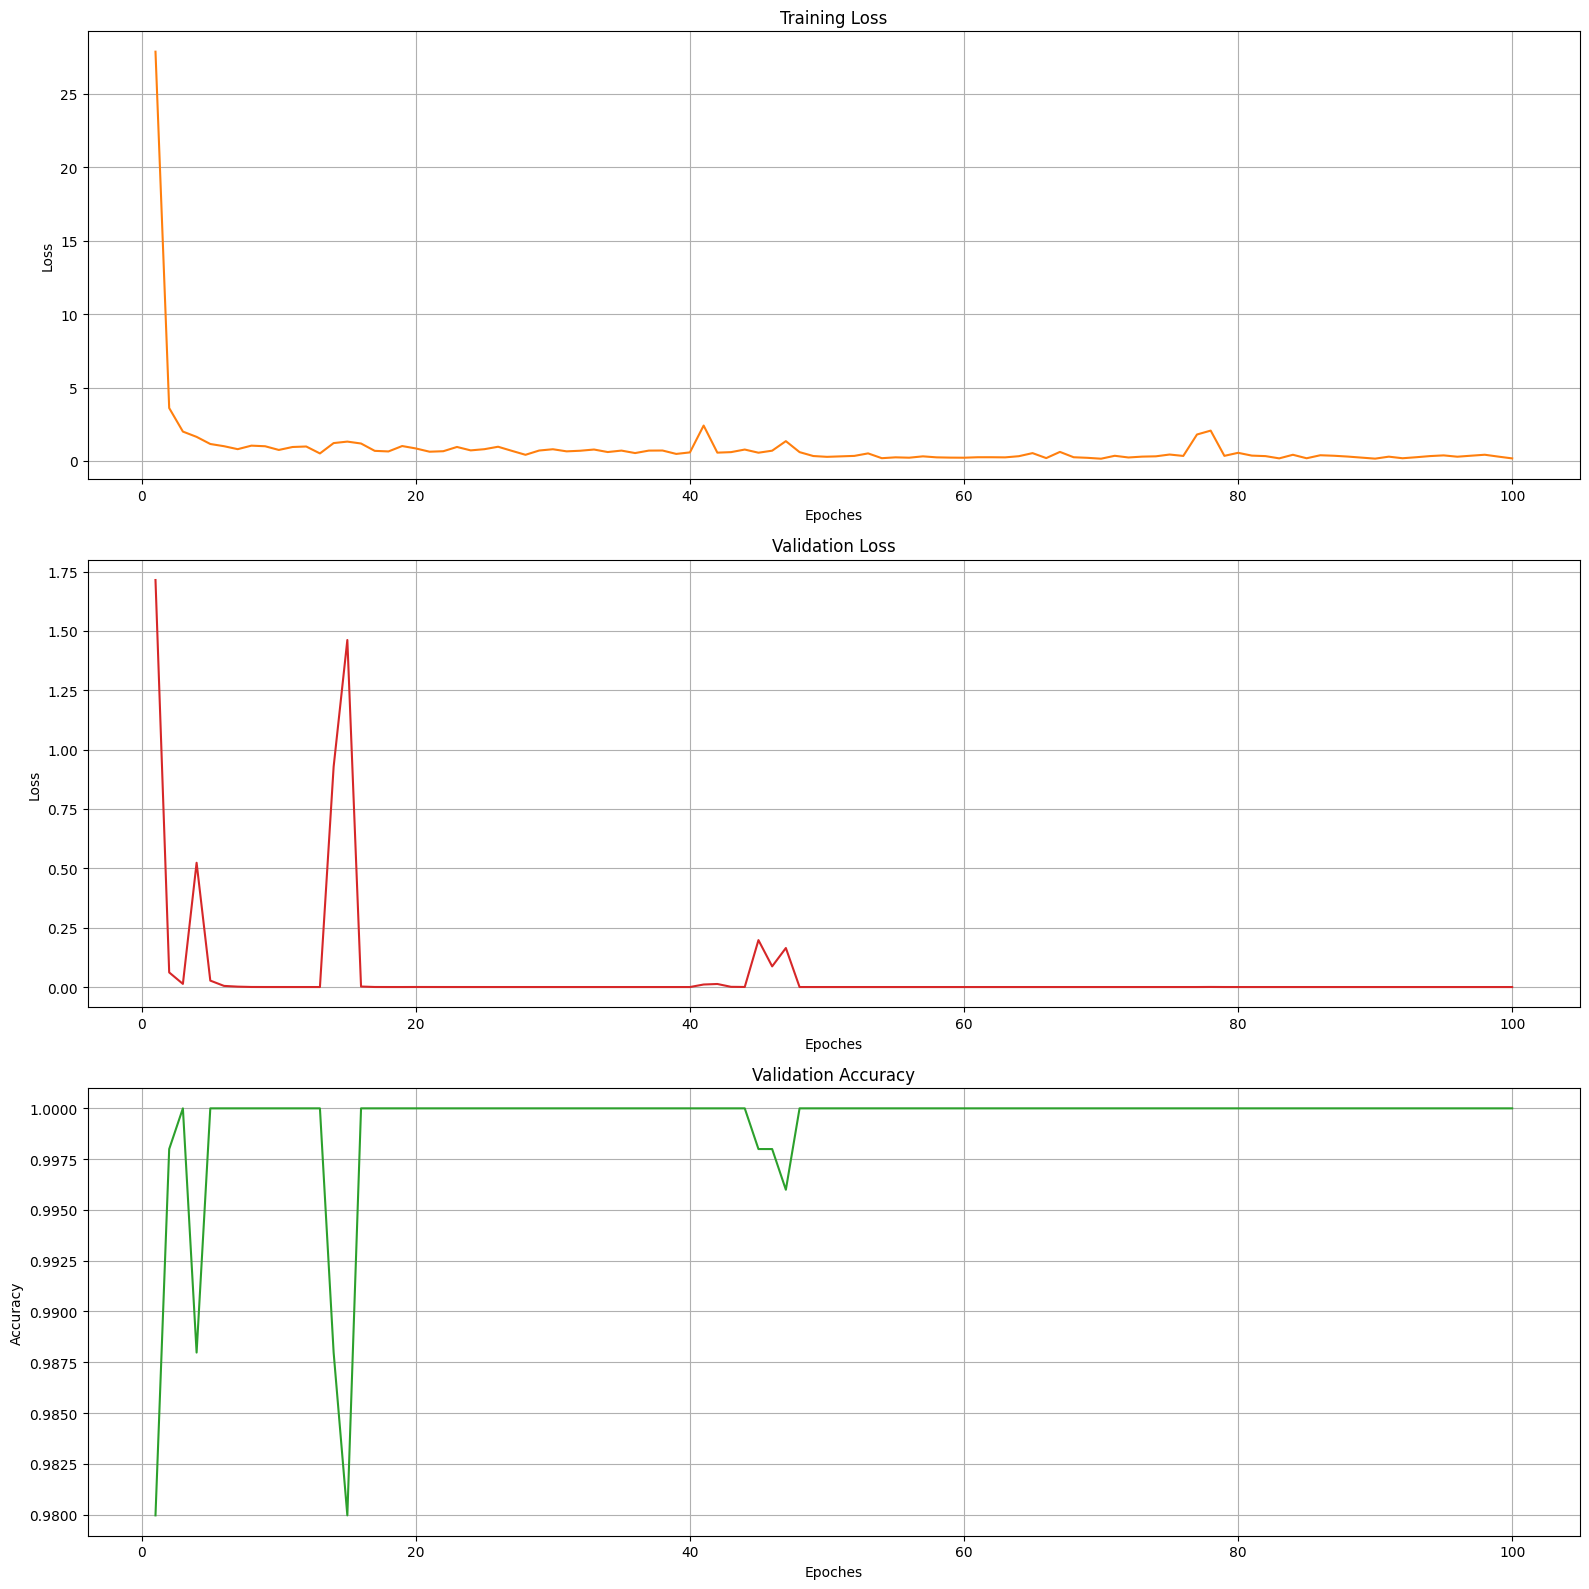

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ChurnModel(input_dim=X_train.shape[1])

train(model, train_loader, val_loader, device,epochs=100)